# Chapter 2: Artificial Neural Networks

This notebook collects the runnable examples of *Chapter 2: Artificial Neural Networks* from the textbook *Computational and Biological Intelligence* (A. Movasagh). Run the cells in order; each example is independent unless noted. Figures are also saved as PNG files in this folder.

## Learning objectives

After working through this notebook you should be able to:

- explain the structure of the biological neuron and its correspondence with the artificial neuron.
- compute the output of a neuron from its weights, bias, and activation function.
- compare the properties and uses of the Sigmoid, Tanh, ReLU, and Softmax activation functions.
- compute and interpret the MSE and cross-entropy loss functions.
- describe the gradient descent algorithm and the effect of the learning rate.
- implement a two-layer network with backpropagation from scratch.


In [1]:
%matplotlib inline

## Example 2.1: Implementing an artificial neuron from scratch

Script version: `example_2_1.py`

In [2]:
# Example 2.1: Implementing an artificial neuron from scratch
import numpy as np
 
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
 
# Three inputs (e.g., three normalized blood test markers)
x = np.array([0.8, 0.2, 0.5])
# The weight of each input and the neuron's bias
w = np.array([0.9, -0.4, 0.6])
b = -0.3
 
z = np.dot(w, x) + b          # step 1: weighted sum  (Σ wi*xi + b)
y = sigmoid(z)                # step 2: activation function
 
print("Weighted inputs w*x :", w * x)
print("Net input z         :", round(z, 3))
print("Output y = sigmoid(z):", round(y, 3))

Weighted inputs w*x : [ 0.72 -0.08  0.3 ]
Net input z         : 0.64
Output y = sigmoid(z): 0.655


## Example 2.2: Implementing and plotting activation functions

Script version: `example_2_2.py`

z = [-2.  -0.5  0.   0.5  2. ]
Binary step : [0. 0. 1. 1. 1.]
Linear      : [-2.  -0.5  0.   0.5  2. ]
Sigmoid     : [0.119 0.378 0.5   0.622 0.881]
Tanh        : [-0.964 -0.462  0.     0.462  0.964]
ReLU        : [0.  0.  0.  0.5 2. ]
Leaky ReLU  : [-0.2  -0.05  0.    0.5   2.  ]
ELU         : [-0.865 -0.393  0.     0.5    2.   ]


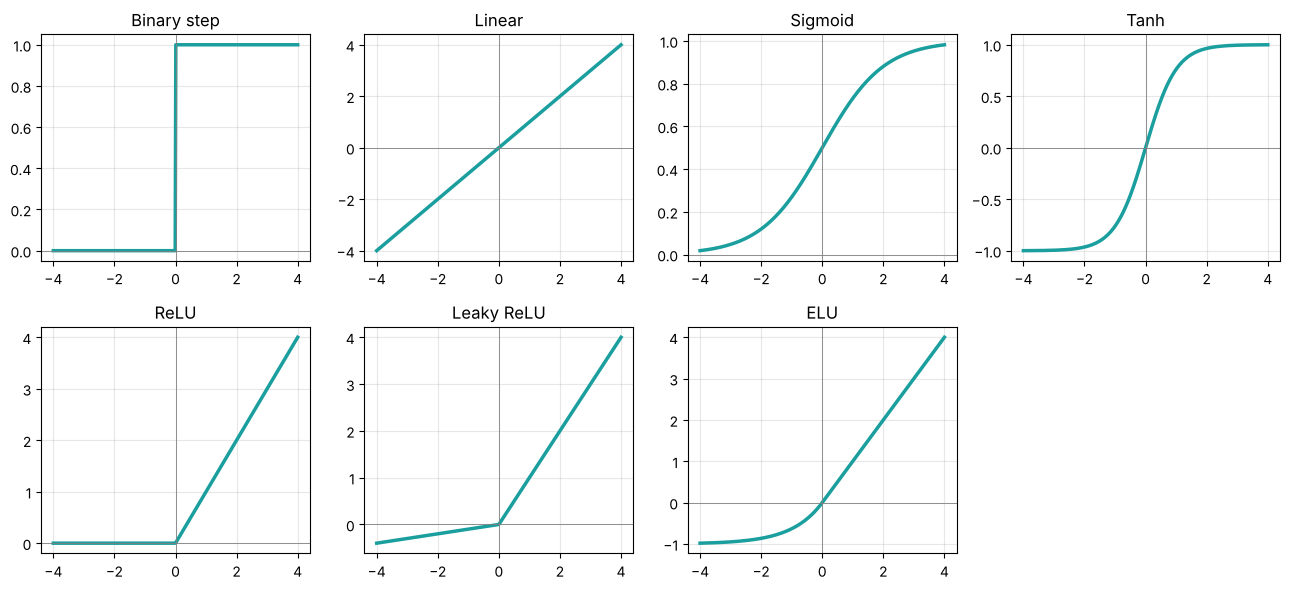

In [3]:
# Example 2.2: Common activation functions and their plots
import numpy as np
import matplotlib.pyplot as plt
 
def step(z):        return np.where(z >= 0, 1.0, 0.0)
def linear(z):      return z
def sigmoid(z):     return 1 / (1 + np.exp(-z))
def tanh(z):        return np.tanh(z)
def relu(z):        return np.maximum(0, z)
def leaky_relu(z, a=0.1): return np.where(z > 0, z, a * z)
def elu(z, a=1.0):  return np.where(z > 0, z, a * (np.exp(z) - 1))
 
funcs = [("Binary step", step), ("Linear", linear), ("Sigmoid", sigmoid),
         ("Tanh", tanh), ("ReLU", relu), ("Leaky ReLU", leaky_relu), ("ELU", elu)]
 
z = np.array([-2.0, -0.5, 0.0, 0.5, 2.0])
print("z =", z)
for name, f in funcs:
    print(f"{name:<12}:", np.round(f(z), 3))
 
zz = np.linspace(-4, 4, 400)
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, (name, f) in zip(axes.ravel(), funcs):
    ax.plot(zz, f(zz), lw=2.5, color="#1b9e9e")
    ax.axhline(0, c="gray", lw=0.6); ax.axvline(0, c="gray", lw=0.6)
    ax.set_title(name); ax.grid(alpha=0.3)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("fig2_1.png", dpi=300)

## Example 2.3: The Softmax function on the output of the last layer

Script version: `example_2_3.py`

In [4]:
# Example 2.3: The Softmax function — converting layer outputs into probabilities
import numpy as np
 
def softmax(z):
    e = np.exp(z - np.max(z))     # subtract max for numerical stability
    return e / e.sum()
 
logits = np.array([1.3, 5.1, 2.2, 0.7, 1.1])   # raw output of the last layer
p = softmax(logits)
print("Logits       :", logits)
print("Probabilities:", p.round(2))
print("Sum of probs :", round(p.sum(), 6))
print("Predicted class index:", int(np.argmax(p)))

Logits       : [1.3 5.1 2.2 0.7 1.1]
Probabilities: [0.02 0.9  0.05 0.01 0.02]
Sum of probs : 1.0
Predicted class index: 1


## Example 2.4: The perceptron succeeds on AND but fails on XOR

Script version: `example_2_4.py`

In [5]:
# Example 2.4: Single-layer perceptron — succeeds on AND, fails on XOR
import numpy as np
 
def train_perceptron(X, y, epochs=20, lr=0.1):
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(epochs):
        for xi, ti in zip(X, y):
            pred = 1 if xi @ w + b >= 0 else 0
            w += lr * (ti - pred) * xi          # perceptron learning rule
            b += lr * (ti - pred)
    return w, b
 
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
for name, y in [("AND", np.array([0, 0, 0, 1])), ("XOR", np.array([0, 1, 1, 0]))]:
    w, b = train_perceptron(X, y)
    pred = (X @ w + b >= 0).astype(int)
    print(f"{name}: targets {y} predictions {pred} accuracy {np.mean(pred == y):.2f}")

AND: targets [0 0 0 1] predictions [0 0 0 1] accuracy 1.00
XOR: targets [0 1 1 0] predictions [1 1 0 0] accuracy 0.50


## Example 2.5: Computing the MSE, MAE, and cross-entropy loss functions

Script version: `example_2_5.py`

In [6]:
# Example 2.5: Computing the MSE and cross-entropy loss functions
import numpy as np
 
# Regression: actual and predicted values
y_true = np.array([3.0, -0.5, 2.0, 7.0])
y_pred = np.array([2.5,  0.0, 2.0, 8.0])
mse = np.mean((y_true - y_pred) ** 2)
mae = np.mean(np.abs(y_true - y_pred))
print("MSE =", mse, "| MAE =", mae)
 
# Binary classification: predicted probability of class 1
t = np.array([1, 0, 1, 1])
p_good = np.array([0.9, 0.1, 0.8, 0.95])
p_bad  = np.array([0.4, 0.7, 0.3, 0.5])
def bce(t, p): return -np.mean(t * np.log(p) + (1 - t) * np.log(1 - p))
print("Binary cross-entropy (good model):", round(bce(t, p_good), 4))
print("Binary cross-entropy (bad model) :", round(bce(t, p_bad), 4))

MSE = 0.375 | MAE = 0.5
Binary cross-entropy (good model): 0.1213
Binary cross-entropy (bad model) : 1.0043


## Example 2.6: Gradient descent and the effect of the learning rate

Script version: `example_2_6.py`

lr=0.05  final w =     2.176 | final J =      1.678
lr=0.3   final w =     3.000 | final J =      1.000
lr=1.02  final w =    10.204 | final J =     52.894


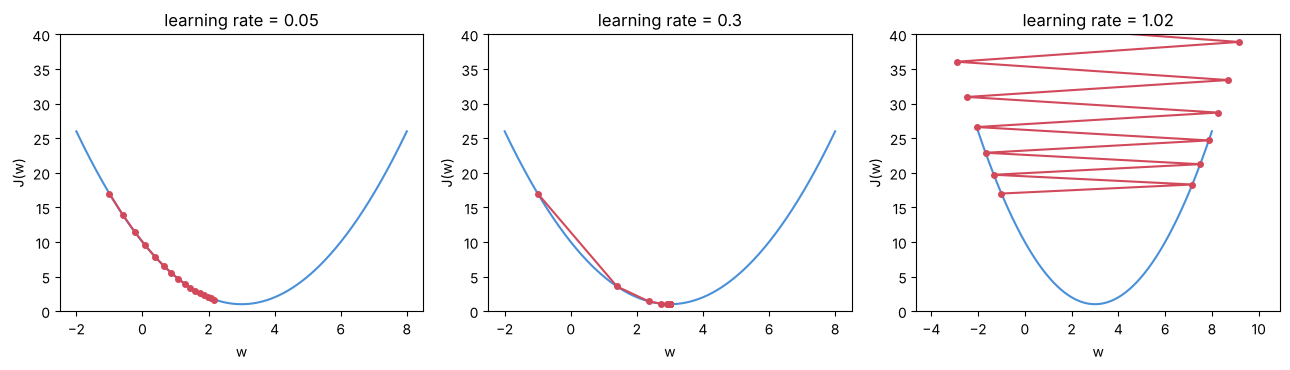

In [7]:
# Example 2.6: Gradient descent on a simple cost function and the effect of the learning rate
import numpy as np
import matplotlib.pyplot as plt
 
J  = lambda w: (w - 3) ** 2 + 1        # cost function, minimum at w = 3
dJ = lambda w: 2 * (w - 3)             # its derivative (gradient)
 
def gradient_descent(w0, lr, steps=15):
    path = [w0]
    for _ in range(steps):
        w0 = w0 - lr * dJ(w0)          # w <- w - η * dJ/dw
        path.append(w0)
    return np.array(path)
 
ws = np.linspace(-2, 8, 300)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, lr in zip(axes, [0.05, 0.3, 1.02]):
    p = gradient_descent(-1.0, lr)
    print(f"lr={lr:<5} final w = {p[-1]:9.3f} | final J = {J(p[-1]):10.3f}")
    ax.plot(ws, J(ws), c="#4a90d9")
    ax.plot(p, J(p), "o-", c="#d1495b", ms=4)
    ax.set_ylim(0, 40); ax.set_title(f"learning rate = {lr}")
    ax.set_xlabel("w"); ax.set_ylabel("J(w)")
plt.tight_layout(); plt.savefig("fig2_2.png", dpi=300)

## Example 2.7: Getting stuck in a local minimum

Script version: `example_2_7.py`

start w=-2.2 -> converged to w=-1.121, C(w)=1.369
start w= 1.8 -> converged to w=3.648, C(w)=1.071


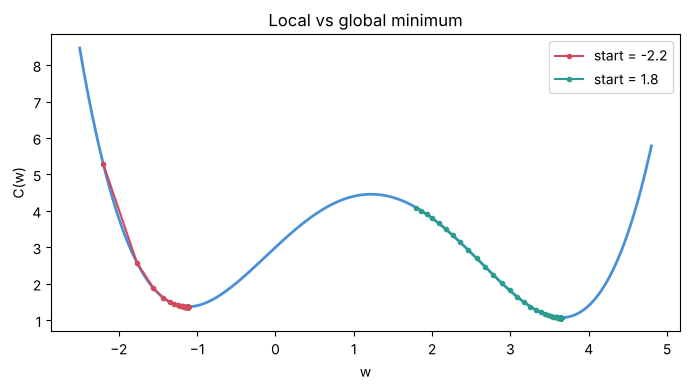

In [8]:
# Example 2.7: Local and global minima of a non-convex function
import numpy as np
import matplotlib.pyplot as plt
 
C  = lambda w: 0.1 * w**4 - 0.5 * w**3 - 0.2 * w**2 + 2 * w + 3
dC = lambda w: 0.4 * w**3 - 1.5 * w**2 - 0.4 * w + 2
 
def descend(w, lr=0.05, steps=200):
    path = [w]
    for _ in range(steps):
        w -= lr * dC(w); path.append(w)
    return np.array(path)
 
ws = np.linspace(-2.5, 4.8, 400)
plt.figure(figsize=(7, 4))
plt.plot(ws, C(ws), c="#4a90d9", lw=2)
for start, color in [(-2.2, "#d1495b"), (1.8, "#2a9d8f")]:
    p = descend(start)
    print(f"start w={start:>4} -> converged to w={p[-1]:.3f}, C(w)={C(p[-1]):.3f}")
    plt.plot(p, C(p), "o-", c=color, ms=3, label=f"start = {start}")
plt.xlabel("w"); plt.ylabel("C(w)"); plt.legend(); plt.title("Local vs global minimum")
plt.tight_layout(); plt.savefig("fig2_3.png", dpi=300)

## Example 2.8: Comparing SGD, Momentum, and Adam

Script version: `example_2_8.py`

SGD       final point = [-0.777  0.   ] | f = 0.0604
Momentum  final point = [0.317 0.077] | f = 0.0218
Adam      final point = [ 0.053 -0.069] | f = 0.0099


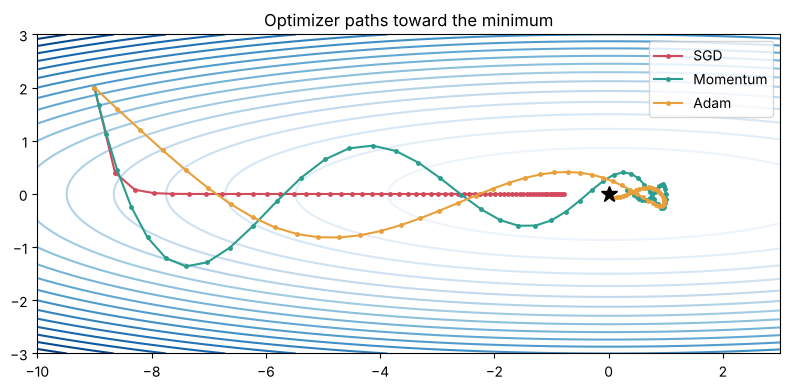

In [9]:
# Example 2.8: Comparing optimizers — SGD, Momentum, and Adam on a cost surface
import numpy as np
import matplotlib.pyplot as plt
 
f  = lambda x, y: 0.1 * x**2 + 2 * y**2           # elongated bowl
gf = lambda x, y: np.array([0.2 * x, 4 * y])
 
def run(opt, steps=60, lr=0.4):
    p = np.array([-9.0, 2.0]); v = np.zeros(2); m = np.zeros(2); s = np.zeros(2)
    path = [p.copy()]
    for t in range(1, steps + 1):
        g = gf(*p)
        if opt == "SGD":
            p -= lr * 0.5 * g
        elif opt == "Momentum":
            v = 0.9 * v + g;  p -= lr * 0.1 * v
        elif opt == "Adam":
            m = 0.9 * m + 0.1 * g;  s = 0.999 * s + 0.001 * g**2
            mh, sh = m / (1 - 0.9**t), s / (1 - 0.999**t)
            p -= lr * mh / (np.sqrt(sh) + 1e-8)
        path.append(p.copy())
    return np.array(path)
 
xs, ys = np.meshgrid(np.linspace(-10, 3, 200), np.linspace(-3, 3, 200))
plt.figure(figsize=(8, 4))
plt.contour(xs, ys, f(xs, ys), levels=20, cmap="Blues")
for opt, c in [("SGD", "#d1495b"), ("Momentum", "#2a9d8f"), ("Adam", "#e9a03b")]:
    path = run(opt)
    print(f"{opt:<9} final point = {path[-1].round(3)} | f = {f(*path[-1]):.4f}")
    plt.plot(path[:, 0], path[:, 1], "o-", ms=2.5, c=c, label=opt)
plt.plot(0, 0, "k*", ms=12); plt.legend(); plt.title("Optimizer paths toward the minimum")
plt.tight_layout(); plt.savefig("fig2_5.png", dpi=300)

## Example 2.9: A two-layer network with backpropagation from scratch

Script version: `example_2_9.py`

Final loss: 0.00034
input [0 0] -> output 0.007 -> class 0
input [0 1] -> output 0.981 -> class 1
input [1 0] -> output 0.981 -> class 1
input [1 1] -> output 0.024 -> class 0


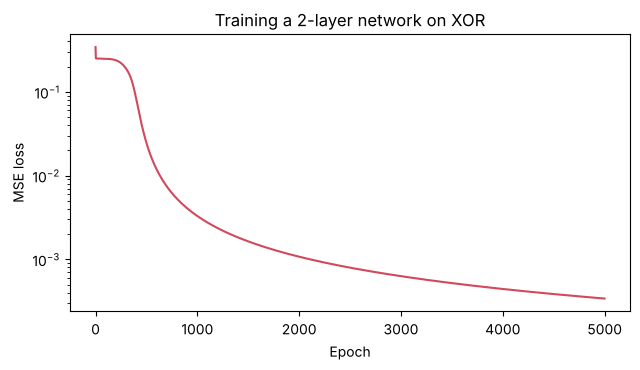

In [10]:
# Example 2.9: A two-layer network from scratch with backpropagation to solve the XOR problem
import numpy as np
import matplotlib.pyplot as plt
 
rng = np.random.default_rng(0)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)
 
sig = lambda z: 1 / (1 + np.exp(-z))
W1, b1 = rng.normal(0, 1, (2, 4)), np.zeros((1, 4))   # input -> hidden (4 neurons)
W2, b2 = rng.normal(0, 1, (4, 1)), np.zeros((1, 1))   # hidden -> output
lr, losses = 1.0, []
 
for epoch in range(5000):
    # --- forward propagation ---
    h = sig(X @ W1 + b1)
    out = sig(h @ W2 + b2)
    loss = np.mean((y - out) ** 2)
    losses.append(loss)
    # --- backward propagation (chain rule) ---
    d_out = (out - y) * out * (1 - out)
    d_h = (d_out @ W2.T) * h * (1 - h)
    W2 -= lr * h.T @ d_out;  b2 -= lr * d_out.sum(0, keepdims=True)
    W1 -= lr * X.T @ d_h;    b1 -= lr * d_h.sum(0, keepdims=True)
 
print("Final loss:", round(losses[-1], 5))
for xi, oi in zip(X, out):
    print(f"input {xi.astype(int)} -> output {oi[0]:.3f} -> class {int(oi[0] > 0.5)}")
 
plt.figure(figsize=(6.5, 3.8))
plt.plot(losses, c="#d1495b"); plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("MSE loss"); plt.title("Training a 2-layer network on XOR")
plt.tight_layout(); plt.savefig("fig2_4.png", dpi=300)

## Example 2.10: A multilayer perceptron for breast cancer diagnosis

Script version: `example_2_10.py`

In [11]:
# Example 2.10: A multilayer neural network with scikit-learn for breast cancer diagnosis
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, classification_report
 
X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
 
model = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(32, 16),   # two hidden layers
                  activation="relu", solver="adam",
                  learning_rate_init=0.001, max_iter=500,
                  early_stopping=True, random_state=0))
model.fit(X_tr, y_tr)
 
mlp = model[-1]
print("Layers (weights shapes):", [w.shape for w in mlp.coefs_])
print("Epochs run:", mlp.n_iter_)
print("Test accuracy:", round(model.score(X_te, y_te), 3))
print("Confusion matrix:\n", confusion_matrix(y_te, model.predict(X_te)))
print(classification_report(y_te, model.predict(X_te),
                            target_names=["malignant", "benign"], digits=3))

Layers (weights shapes): [(30, 32), (32, 16), (16, 1)]
Epochs run: 54
Test accuracy: 0.965
Confusion matrix:
 [[49  4]
 [ 1 89]]
              precision    recall  f1-score   support

   malignant      0.980     0.925     0.951        53
      benign      0.957     0.989     0.973        90

    accuracy                          0.965       143
   macro avg      0.968     0.957     0.962       143
weighted avg      0.966     0.965     0.965       143



## Example 2.11: The effect of the L2 regularization coefficient on overfitting

Script version: `example_2_11.py`

lambda=1e-09  train MSE=0.008 | validation MSE=    0.254 | ||w||^2 =    7777464.0
lambda=0.01   train MSE=0.020 | validation MSE=    0.044 | ||w||^2 =          5.2
lambda=10     train MSE=0.075 | validation MSE=    0.145 | ||w||^2 =          0.1


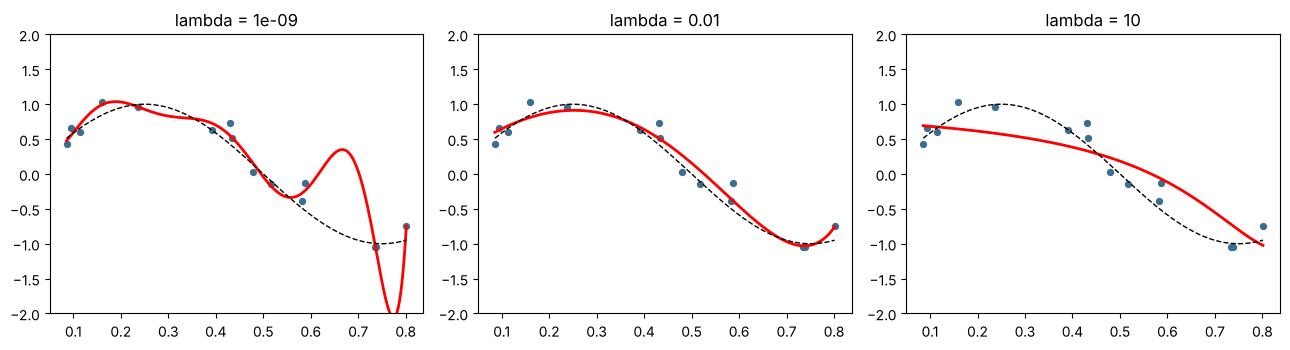

In [12]:
# Example 2.11: L2 regularization — taming the overfitting of a degree-15 polynomial model
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
 
rng = np.random.default_rng(3)
x = np.sort(rng.uniform(0, 1, 15)); y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, 15)
xv = rng.uniform(x.min(), x.max(), 200); yv = np.sin(2 * np.pi * xv) + rng.normal(0, 0.2, 200)
xs = np.linspace(x.min(), x.max(), 300)
 
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, lam in zip(ax, [1e-9, 1e-2, 10.0]):
    model = make_pipeline(PolynomialFeatures(15), StandardScaler(), Ridge(alpha=lam))
    model.fit(x[:, None], y)
    tr = mean_squared_error(y, model.predict(x[:, None])); va = mean_squared_error(yv, model.predict(xv[:, None]))
    w = model[-1].coef_
    print(f"lambda={lam:<6g} train MSE={tr:.3f} | validation MSE={va:9.3f} | ||w||^2 = {np.sum(w**2):12.1f}")
    a.scatter(x, y, s=18, c="#3C6E8F"); a.plot(xs, model.predict(xs[:, None]), "r", lw=2)
    a.plot(xs, np.sin(2 * np.pi * xs), "k--", lw=1); a.set_ylim(-2, 2); a.set_title(f"lambda = {lam:g}")
plt.tight_layout(); plt.savefig("fig2_6.png", dpi=300)